# HNODE: Plasma Gun

This notebook trains a conditional HNODE on 2D plasma gun (horseshoe MITL) simulations at three
peak voltage levels. The state is a 64-dimensional latent vector produced by a **learned Swin-V2
autoencoder** trained end-to-end with the dynamics model. The simulation domain has an irregular
boundary, handled via a binary mask. The model is conditioned on a single scalar `z ∈ {-1, 0, 1}`
encoding the peak voltage level.

**Data**: Horseshoe2D plasma simulation snapshots (7 fields, padded to 256×768) stored as `.pt` files.
Not presently available to the public, but we do provide a checkpoint and the first few frames so that a long rollout can be performed.

**Checkpoint**: Set `CHECKPOINT_PATH` to a `.pt` file to resume from a saved checkpoint,
or set it to `None` to train from scratch.

In [38]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import random
from torch.utils.data import Dataset, DataLoader
from einops import rearrange
import torch.nn.functional as F

from hybrid_node_solver import HybridNODESolver
from neural_networks import CrossAttnTransformer
from swin_transformer_v2 import SwinEncoder, SwinDecoder
from soap import SOAP

torch.set_default_dtype(torch.float64)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
print(f"Using device: {device}")

Using device: cuda


## Configuration

In [ ]:
# Path to the directory containing the Horseshoe2D trajectory subdirectories.
DATA_PATH = "./plasma_gun_frames"

# Path to a saved checkpoint to resume training, or None to train from scratch.
CHECKPOINT_PATH = "./swin_plasma_e2e_redo_part_2.pth"
SAVE_PATH = "plasma_gun_checkpoint.pth"
SAVE_EVERY = 100

## Dataset

In [40]:
# Subdirectory names — one per (Vpeak, seed) combination.
# z ∈ {-1, 0, 1} encodes Vpeak ∈ {0.009, 0.010, 0.011}.
DIRECTORIES = [
    "example_traj",
]

# z values aligned with DIRECTORIES above (-1 / 0 / 1 for the three Vpeak levels)
DIRECTORY_Z_MAP = torch.tensor([0.0])


class Horseshoe2DDataset(Dataset):
    """
    Loads Horseshoe2D plasma gun simulation frames.

    Directory structure::

        parent_directory/
            stats.pt                          # mask, per-channel mean and std
            <subdir_name>/
                frames/
                    frame_000000.pt
                    frame_000001.pt
                    ...
    """

    def __init__(
        self,
        parent_directory,
        directories,
        num_time_steps_per_data_sample,
        N=3,
        deterministic_sampling=False,
        random_seed=None,
    ):
        self.parent_directory = parent_directory
        self.directories = directories
        self.num_time_steps_per_data_sample = num_time_steps_per_data_sample
        self.N = N

        if deterministic_sampling and random_seed is not None:
            self.generator = torch.Generator()
            self.generator.manual_seed(random_seed)
        else:
            self.generator = None

        frame_counts = []
        for d in directories:
            files = glob.glob(os.path.join(parent_directory, d, "frames", "frame_*.pt"))
            frame_counts.append(len(files))
        assert all(fc == frame_counts[0] for fc in frame_counts)
        self.num_frames = frame_counts[0]
        self.num_subdirectories = len(directories)

        stats = torch.load(os.path.join(parent_directory, "stats.pt"))
        self.mask = stats["mask"].double().unsqueeze(0).unsqueeze(0)
        self.data_mean = stats["mean"].double().unsqueeze(0).unsqueeze(-1).unsqueeze(-1)
        self.data_std = stats["std"].double().unsqueeze(0).unsqueeze(-1).unsqueeze(-1)

        self.effective_length_per_subdir = (
            self.num_frames - 2 * num_time_steps_per_data_sample - 1
        )
        self.effective_length_total = (
            self.num_subdirectories * self.effective_length_per_subdir
        )
        # assert self.effective_length_per_subdir > 0

        self.directory_index_to_z_map = DIRECTORY_Z_MAP

    def __len__(self):
        # return self.effective_length_total
        return 1

    def __getitem__(self, idx):
        directory_index = idx // self.effective_length_per_subdir
        start_index = idx % self.effective_length_per_subdir

        left_mortar_indices = torch.tensor(
            [start_index, start_index + 1, start_index + 2]
        )
        u_hat_indices = (
            torch.randperm(self.num_time_steps_per_data_sample)[: self.N].sort().values
        )
        u_hat_indices[0] = 0

        frame_offsets = 2 * u_hat_indices + 2
        frames_to_grab = torch.cat([left_mortar_indices, start_index + frame_offsets])

        files_to_grab = [
            os.path.join(
                self.parent_directory,
                self.directories[directory_index],
                "frames",
                f"frame_{i:06d}.pt",
            )
            for i in frames_to_grab
        ]
        data = torch.stack([torch.load(f).double() for f in files_to_grab])
        data = (data - self.data_mean) / self.data_std
        data = torch.cat([data, self.mask.repeat(data.shape[0], 1, 1, 1)], dim=1)

        z = self.directory_index_to_z_map[directory_index]
        return data, u_hat_indices, z.unsqueeze(0)


latent_dim = 64
dt = 1e-2
num_time_steps_per_data_sample = 256
N = 32  # number of training rollouts
batch_size = 1

delta_t = dt * num_time_steps_per_data_sample / N
N_t = (
    num_time_steps_per_data_sample // N
) + 1  # collocation points per rollout (M = N_t - 1)

dataset = Horseshoe2DDataset(
    DATA_PATH,
    DIRECTORIES,
    num_time_steps_per_data_sample,
    N=4,
)
dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=4,
    drop_last=True,
    pin_memory=True,
    persistent_workers=True,
)

print(
    f"Dataset size: {len(dataset)}, delta_t={delta_t:.4f}, N_t={N_t} (M={N_t-1} intervals)"
)

Dataset size: 1, delta_t=0.0800, N_t=9 (M=8 intervals)


## Model

In [41]:
def pad_sample(sample):
    """Pad spatial dimensions to (256, 768)."""
    pad_height = 256 - sample.shape[-2]
    pad_width = 768 - sample.shape[-1]
    return F.pad(sample, (0, pad_width, 0, pad_height))


encoder = SwinEncoder(
    img_size=(256, 768),
    patch_size=4,
    in_chans=7,
    latent_dim=latent_dim,
    embed_dim=96,
    depths=(2, 2, 6, 2),
    num_heads=(3, 6, 12, 24),
    window_size=(8, 8),
    mlp_ratio=4,
    drop=0.0,
    attn_drop=0.0,
    drop_path_rate=0.0,
    final_channels=64,
).to(device)

decoder = SwinDecoder(
    img_size=(256, 768),
    patch_size=4,
    out_chans=7,
    latent_dim=latent_dim,
    embed_dim=96,
    depths=(2, 2, 6, 2),
    num_heads=(3, 6, 12, 24),
    window_size=(8, 8),
    mlp_ratio=4,
    drop=0.0,
    attn_drop=0.0,
    drop_path_rate=0.0,
).to(device)

encoder = torch.compile(encoder)
decoder = torch.compile(decoder)

nn_rhs_model = CrossAttnTransformer(
    problem_dim=latent_dim,
    latent_dim=64 * 4,
    num_blocks=3,
    num_heads=4,
    z_dim=1,
    dropout_rate=0,
    activation=torch.nn.Tanh(),
    use_self_attention_z_block=True,
).to(device)

solver = HybridNODESolver(
    nn_rhs_model,
    delta_t,
    N_t,
    latent_dim,
    N,
    backprop_type="matrix_free",
    use_manual_jacobian=True,
    use_sparse_solver=False,
    use_cpu_solver=False,
    verbose=False,
    device=device,
)

n_params = sum(
    p.numel()
    for p in list(encoder.parameters())
    + list(decoder.parameters())
    + list(nn_rhs_model.parameters())
)
print(f"Total parameters: {n_params:,}")

Total parameters: 72,235,779


## Optimizer and Checkpoint

In [42]:
def get_param_groups(models, weight_decay=1e-4):
    """Separate transformer params into decay / no-decay groups (standard practice)."""
    if not isinstance(models, (list, tuple)):
        models = [models]
    decay, no_decay = [], []
    for model in models:
        for name, param in model.named_parameters():
            if not param.requires_grad:
                continue
            if (
                param.ndim <= 1
                or "bias" in name
                or "norm" in name.lower()
                or "ln" in name
            ):
                no_decay.append(param)
            else:
                decay.append(param)
    return [
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ]


optimizer = SOAP(
    get_param_groups([nn_rhs_model, encoder, decoder]),
    precondition_frequency=10,
    lr=1e-4,
)

loss_history = []

if CHECKPOINT_PATH is not None:
    if os.path.exists(CHECKPOINT_PATH):
        checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
        encoder.load_state_dict(checkpoint["encoder"])
        decoder.load_state_dict(checkpoint["decoder"])
        nn_rhs_model.load_state_dict(checkpoint["nn_rhs_model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        loss_history = checkpoint["loss_history"]
        print(f"Loaded checkpoint from {CHECKPOINT_PATH} ({len(loss_history)} steps)")
    else:
        print(f"Checkpoint not found at {CHECKPOINT_PATH}, training from scratch.")

Loaded checkpoint from /scratch/tmp/kinch/plasma/swin_plasma_e2e_redo_part_2.pth (144900 steps)


## Training

In [43]:
def save_checkpoint():
    torch.save(
        {
            "encoder": encoder.state_dict(),
            "decoder": decoder.state_dict(),
            "nn_rhs_model": nn_rhs_model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "loss_history": loss_history,
        },
        SAVE_PATH,
    )


# Pre-compute padded mask on device
mask = dataset.mask.repeat(1, 1, 1, 1)
padded_mask = pad_sample(mask).to(device)

solver.verbose = False
NUM_EPOCHS = 0

for epoch in range(NUM_EPOCHS):
    for itr, (frames, u_hat_indices_to_decode, zs) in enumerate(dataloader):
        frames = frames.to(device)
        u_hat_indices_to_decode = u_hat_indices_to_decode.to(device)

        padded_frames = pad_sample(frames)
        padded_frames = torch.where(padded_mask > 0, padded_frames, 0.0)

        left_frames = rearrange(padded_frames[:, :3], "B T C H W -> (B T) C H W")
        left_tgt_frames = rearrange(padded_frames[:, :2], "B T C H W -> (B T) C H W")
        target_frames = rearrange(padded_frames[:, 3:], "B T C H W -> (B T) C H W")

        left_latents = encoder(left_frames)
        left_latents_to_decode = rearrange(
            rearrange(left_latents, "(B T) L -> B T L", B=batch_size)[:, :2],
            "B T L -> (B T) L",
        )
        recon_left = decoder(left_latents_to_decode)
        recon_left = torch.where(padded_mask > 0, recon_left, 0.0)

        left_latents = rearrange(left_latents, "(B T) L -> B T L", B=batch_size)
        batch_dict = {
            "J_init": (left_latents[:, 2, :] - left_latents[:, 0, :]) / dt,
            "u_init": left_latents[:, 1, :],
            "z": zs.to(device),
        }
        _, u_hat_rollout = solver.evolve_batch(batch_dict)

        u_hats_to_decode = torch.stack(
            [
                u_hats[indices]
                for u_hats, indices in zip(u_hat_rollout, u_hat_indices_to_decode)
            ]
        )
        u_hats_to_decode = rearrange(u_hats_to_decode, "B T L -> (B T) L")
        recon = decoder(u_hats_to_decode)
        recon = torch.where(padded_mask > 0, recon, 0.0)

        recon = torch.cat([recon_left, recon], dim=0)
        target_frames = torch.cat([left_tgt_frames, target_frames], dim=0)

        loss = torch.nn.functional.l1_loss(
            recon[padded_mask.expand_as(recon) > 0],
            target_frames[padded_mask.expand_as(target_frames) > 0],
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())

        if len(loss_history) % 10 == 0:
            torch.cuda.empty_cache()
        if len(loss_history) % SAVE_EVERY == 0:
            save_checkpoint()

        print(f"Epoch {epoch} | Batch {itr}/{len(dataloader)} | Loss {loss.item():.6e}")

## Evaluation

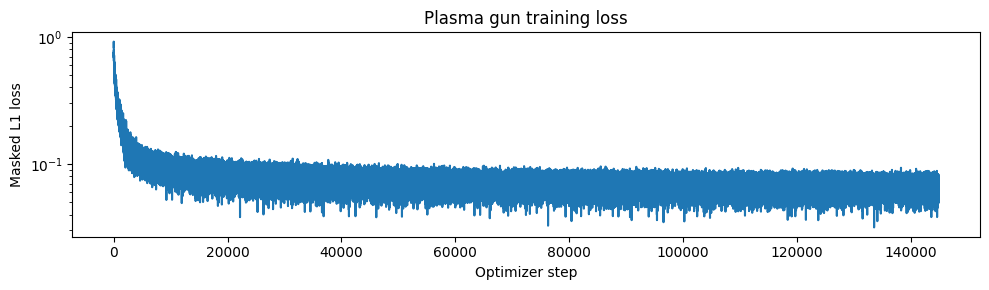

In [44]:
# Loss curve
fig, ax = plt.subplots(figsize=(10, 3))
ax.semilogy(loss_history)
ax.set_xlabel("Optimizer step")
ax.set_ylabel("Masked L1 loss")
ax.set_title("Plasma gun training loss")
plt.tight_layout()
plt.show()

In [45]:
# Long model-only rollout on the bundled plasma-gun trajectory
ROLLOUT_DIRECTORY = DIRECTORIES[0]
START_INDEX = 0
LONG_NUM_ROLLOUTS = 25 * N
RHO_TIME_INDICES = [0, 50, 100, 250, 500, 1000, 2500, 5000]

encoder.eval()
decoder.eval()
nn_rhs_model.eval()
solver.verbose = False
solver.include_mortars = False

mask = dataset.mask
padded_mask = pad_sample(mask).to(device)
mask_cpu = padded_mask[0, 0].cpu().numpy()


def load_normalized_frame(frame_idx):
    frame_path = os.path.join(
        DATA_PATH, ROLLOUT_DIRECTORY, "frames", f"frame_{frame_idx:06d}.pt"
    )
    frame = torch.load(frame_path, map_location="cpu").double()
    frame_norm = (frame - dataset.data_mean[0]) / dataset.data_std[0]
    frame_norm = torch.cat([frame_norm, dataset.mask[0]], dim=0)
    return pad_sample(frame_norm.unsqueeze(0))[0]


def unnormalize_plasma_frame(frame_7ch):
    physical = frame_7ch.clone()
    physical[:6] = physical[:6] * dataset.data_std[0] + dataset.data_mean[0]
    physical[6:] = padded_mask.cpu()[0]
    return physical


with torch.no_grad():
    ic_frames = (
        torch.stack([load_normalized_frame(START_INDEX + i) for i in [0, 1, 2]])
        .unsqueeze(0)
        .to(device)
    )
    ic_frames = torch.where(padded_mask > 0, ic_frames, 0.0)

    left = rearrange(ic_frames, "B T C H W -> (B T) C H W")
    left_latents = rearrange(encoder(left), "(B T) L -> B T L", B=1)
    rollout_batch = {
        "J_init": (left_latents[:, 2, :] - left_latents[:, 0, :]) / dt,
        "u_init": left_latents[:, 1, :],
        "z": torch.tensor(
            [[float(DIRECTORY_Z_MAP[0])]], dtype=torch.float64, device=device
        ),
    }
    _, u_hat_rollout = solver.rollout_batch(
        rollout_batch, num_rollouts=LONG_NUM_ROLLOUTS
    )

    max_time_index = u_hat_rollout.shape[1] - 1
    rho_time_indices = [t for t in RHO_TIME_INDICES if t <= max_time_index]
    selected_latents = u_hat_rollout[:, rho_time_indices, :]
    decoded_norm = rearrange(
        decoder(rearrange(selected_latents, "B T L -> (B T) L")),
        "(B T) C H W -> B T C H W",
        B=1,
    )[0].cpu()

model_frames = torch.stack([unnormalize_plasma_frame(frame) for frame in decoded_norm])
print(f"Rollout latents: {u_hat_rollout.shape}")
print(f"Decoded rho snapshots at latent time indices: {rho_time_indices}")

rebuilding indexers... 
done rebuilding indexers
Rollout latents: torch.Size([1, 6400, 64])
Decoded rho snapshots at latent time indices: [0, 50, 100, 250, 500, 1000, 2500, 5000]


/tmp/ipykernel_85645/588939505.py:49: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


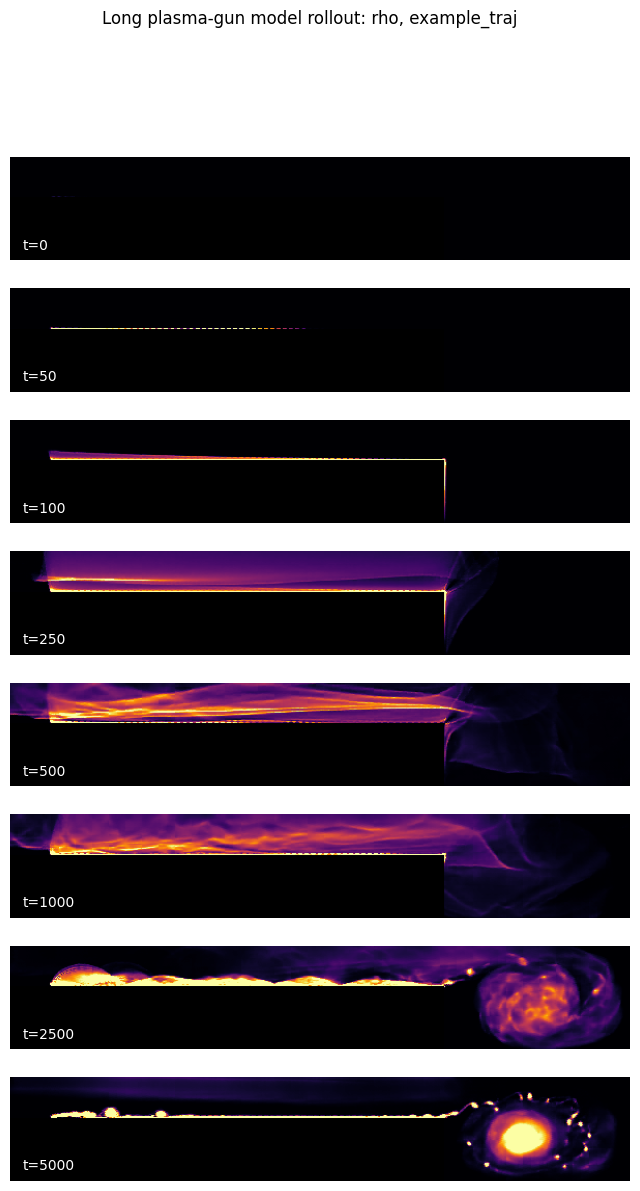

In [46]:
# Model rho snapshots from the long rollout
rho_ch = 5
XLIM = (0, 599)
YLIM = (0, 100)

rho_frames = np.where(mask_cpu > 0, model_frames[:, rho_ch].numpy(), np.nan)
rho_vmin = np.nanpercentile(rho_frames, 2)
rho_vmax = np.nanpercentile(rho_frames, 98)

cmap = plt.get_cmap("inferno").copy()
cmap.set_bad(color="black")

fig, axes = plt.subplots(
    len(rho_time_indices),
    1,
    figsize=(8.0, 1.7 * len(rho_time_indices)),
    squeeze=False,
    gridspec_kw={"hspace": 0.04},
)
label_kw = dict(fontsize=10, color="white")

for row, t_idx in enumerate(rho_time_indices):
    ax = axes[row, 0]
    ax.imshow(
        rho_frames[row],
        origin="lower",
        cmap=cmap,
        vmin=rho_vmin,
        vmax=rho_vmax,
        aspect="equal",
    )
    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.text(
        0.02,
        0.08,
        f"t={t_idx}",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        **label_kw,
    )

fig.suptitle(f"Long plasma-gun model rollout: rho, {ROLLOUT_DIRECTORY}", y=0.98)
plt.tight_layout()
plt.show()